## Geographical Analysis of the Flows through Network Analysis

In [2]:
import pandas as pd
import networkx as nx
import itertools
import json
import matplotlib.pyplot as plt
import powerlaw
import geopandas as gpd
import mapclassify
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from pyproj import Transformer
from scipy.stats import norm

In [3]:
with open('Step 3: Pulizia, trasformazione e analisi sullo storico/Pulizia storico/storico_pulito.json', 'r') as f:
    data = json.load(f)

In [4]:
df = pd.read_csv('Costruzione e Analisi DF/3. Data Understanding and Prep/df_understanding_analysis.csv')

In [5]:
df['regione'].unique()

array(['Calabria', 'Tuscany', 'Lombardy', 'Lazio', 'Veneto', 'Campania',
       'Liguria', 'Piedmont', 'Emilia-Romagna', 'Umbria', 'Apulia',
       'Sicily', 'Sardinia', 'The Marches', 'Trentino-Alto Adige',
       'Friuli Venezia Giulia', 'Abruzzo', 'Basilicate', 'Molise',
       'Aosta Valley'], dtype=object)

In [6]:
mapping_regioni = {
    "Lombardy": "Lombardia",
    "Lazio": "Lazio",
    "Tuscany": "Toscana",
    "Emilia-Romagna": "Emilia-Romagna",
    "Piedmont": "Piemonte",
    "Veneto": "Veneto",
    "Campania": "Campania",
    "Sicily": "Sicilia",
    "Apulia": "Puglia",
    "Friuli Venezia Giulia": "Friuli-Venezia Giulia",
    "Trentino-Alto Adige": "Trentino-Alto Adige/Südtirol",
    "Liguria": "Liguria",
    "Abruzzo": "Abruzzo",
    "Sardinia": "Sardegna",
    "Calabria": "Calabria",
    "The Marches": "Marche",
    "Umbria": "Umbria",
    "Basilicate": "Basilicata",
    "Molise": "Molise",
    "Aosta Valley": "Valle d'Aosta/Vallée d'Aoste"
}

# Applica la mappatura al tuo dataframe
df['regione_it'] = df['regione'].map(mapping_regioni)

In [7]:
def extract_flows_temporal(data, start_year=2020, end_year=2024):
    edges = []
    years = list(range(start_year, end_year))
    
    def get_names(lst):
        names = []
        for x in lst:
            if isinstance(x, dict):
                names.append(x.get("nome_istituzione"))
            else:
                names.append(x)
        return set([n for n in names if n])
    
    for autore, anni in data.items():
        for y in years:
            y1, y2 = str(y), str(y+1)
            
            if y1 not in anni or y2 not in anni:
                continue
            
            inst1 = get_names(anni[y1])
            inst2 = get_names(anni[y2])
            
            # 👇 CORE LOGIC
            stayed = inst1.intersection(inst2)
            left = inst1 - stayed
            entered = inst2 - stayed
            
            # flussi solo per chi cambia davvero
            for u in left:
                for v in entered:
                    edges.append({
                        'source': u,
                        'target': v,
                        'year_from': y1,
                        'year_to': y2
                    })
    
    return pd.DataFrame(edges)

In [8]:
df_edges = extract_flows_temporal(data, start_year=2020, end_year=2024)

In [9]:
df_edges

,source,target,year_from,year_to
0,Mario Negri Institute for Pharmacological Rese...,Ospedale San Giovanni Antica Sede,2020,2021
1,Ospedale San Giovanni Antica Sede,IRCCS Humanitas Research Hospital,2021,2022
2,Ospedale San Giovanni Antica Sede,Mario Negri Institute for Pharmacological Rese...,2021,2022
3,Ospedale San Giovanni Antica Sede,Istituti di Ricovero e Cura a Carattere Scient...,2021,2022
4,Hewlett-Packard (Italy),University of Padua,2020,2021
...,...,...,...,...
36573,University of Turin,Sapienza University of Rome,2021,2022
36574,University of Sannio,European Space Research Institute,2022,2023
36575,Politecnico di Milano,National Institute of Oceanography and Applied...,2022,2023
36576,University of Padua,University of Bologna,2020,2021


In [10]:
# Contiamo le occorrenze per ogni coppia
df_weighted = df_edges.groupby(['source', 'target']).size().reset_index(name='weight')

In [11]:
# Creiamo il grafo NetworkX
G = nx.from_pandas_edgelist(df_weighted, source='source', target='target', edge_attr='weight', create_using=nx.DiGraph())

In [12]:
inst_to_region = dict(zip(df['nome_istituzione'], df['regione_it']))

In [13]:
from collections import defaultdict

flows_region = defaultdict(float)

for u, v, d in G.edges(data=True):
    reg_u = inst_to_region.get(u)
    reg_v = inst_to_region.get(v)
    
    if reg_u and reg_v and reg_u != reg_v:
        flows_region[(reg_u, reg_v)] += d['weight']

In [14]:
G_reg = nx.DiGraph()

for (u, v), w in flows_region.items():
    G_reg.add_edge(u, v, weight=w)

In [15]:
print(f'Il grafo ha {G_reg.number_of_nodes()} nodi e {G_reg.number_of_edges()} links')
print(f'L\'average degree è di: {sum(dict(G_reg.degree()).values())/float(len(G_reg)):.2f}')
print(f'La densità del grafo è {nx.density(G_reg)}.')


Il grafo ha 20 nodi e 336 links
L'average degree è di: 33.60
La densità del grafo è 0.8842105263157894.


In [16]:
# Average clustering coefficient
nx.average_clustering(G_reg)

0.962217520287633

In [17]:
# Transitivity
print(f'La transitivity del network è di {nx.transitivity(G_reg)}')

La transitivity del network è di 0.9494462307967131


In [18]:
# def plot_dist(G):
#     M = nx.to_scipy_sparse_array(G)
#     xmin = min([d[1] for d in G.degree()])
#     indegrees = M.sum(0).ravel()
#     degree = np.bincount(indegrees)
#     fit = powerlaw.Fit(np.array(degree)+1, fit_method='KS')#, xmin=xmin, xmax=max(degree)-xmin,discrete=True)
    
    
#     fig = plt.figure(figsize=(16, 6)) 
#     """ Plot Distribution """
#     plt.subplot(1, 3, 1)
#     plt.plot(range(len(degree)),degree,'b.')   
#     plt.loglog()
#     plt.xlim((min(degree), max(degree)))
#     plt.xlabel('Degree')
#     plt.ylabel('P(k)')


#     """ Plot CDF """
#     plt.subplot(1, 3, 2)
#     fit.plot_cdf()
#     plt.xlabel("Degree")
#     plt.ylabel('CDF')

#     """ Plot CCDF """
#     plt.subplot(1, 3, 3)
#     fit.plot_ccdf()
#     plt.ylabel('CCDF')
#     plt.xlabel('Degree')
#     plt.tight_layout()
#     plt.show()

# plot_dist(G_reg)

In [19]:
sorted([(u,v,d['weight']) for u,v,d in G_reg.edges(data=True)], key=lambda x: -x[2])[:10]

[('Lazio', 'Lombardia', 1553.0),
 ('Lombardia', 'Lazio', 1435.0),
 ('Toscana', 'Lazio', 675.0),
 ('Lazio', 'Toscana', 663.0),
 ('Emilia-Romagna', 'Lazio', 642.0),
 ('Lazio', 'Emilia-Romagna', 609.0),
 ('Campania', 'Lazio', 570.0),
 ('Lombardia', 'Toscana', 533.0),
 ('Emilia-Romagna', 'Lombardia', 530.0),
 ('Lombardia', 'Emilia-Romagna', 491.0)]

In [20]:
for node in G_reg.nodes():
    out_edges = G_reg.out_edges(node, data=True)
    total = sum(d['weight'] for _, _, d in out_edges)
    
    for u, v, d in out_edges:
        if total > 0:
            d['weight_norm'] = d['weight'] / total

In [21]:
sorted([(u,v,d['weight']) for u,v,d in G_reg.edges(data=True)], key=lambda x: -x[2])[:10]

[('Lazio', 'Lombardia', 1553.0),
 ('Lombardia', 'Lazio', 1435.0),
 ('Toscana', 'Lazio', 675.0),
 ('Lazio', 'Toscana', 663.0),
 ('Emilia-Romagna', 'Lazio', 642.0),
 ('Lazio', 'Emilia-Romagna', 609.0),
 ('Campania', 'Lazio', 570.0),
 ('Lombardia', 'Toscana', 533.0),
 ('Emilia-Romagna', 'Lombardia', 530.0),
 ('Lombardia', 'Emilia-Romagna', 491.0)]

In [22]:
print("=== INFO GRAFO ===")
print(f"Nodi: {G_reg.number_of_nodes()}")
print(f"Archi: {G_reg.number_of_edges()}")

# densità
density = nx.density(G_reg)
print(f"Densità: {density:.4f}")

# grado medio
degrees = dict(G_reg.degree())
avg_degree = sum(degrees.values()) / len(degrees)
print(f"Grado medio: {avg_degree:.2f}")

=== INFO GRAFO ===
Nodi: 20
Archi: 336
Densità: 0.8842
Grado medio: 33.60


In [23]:
sorted([(u,v,d['weight']) for u,v,d in G_reg.edges(data=True)], key=lambda x: -x[2])[:10]

[('Lazio', 'Lombardia', 1553.0),
 ('Lombardia', 'Lazio', 1435.0),
 ('Toscana', 'Lazio', 675.0),
 ('Lazio', 'Toscana', 663.0),
 ('Emilia-Romagna', 'Lazio', 642.0),
 ('Lazio', 'Emilia-Romagna', 609.0),
 ('Campania', 'Lazio', 570.0),
 ('Lombardia', 'Toscana', 533.0),
 ('Emilia-Romagna', 'Lombardia', 530.0),
 ('Lombardia', 'Emilia-Romagna', 491.0)]

In [24]:
def run_network_analysis(G, iterations=1000, alpha=0.05):
    edges = list(G.edges())
    real_weights = np.array([G[u][v]['weight'] for u, v in edges])
    
    # Pre-calcola out-strength per ogni nodo sorgente
    out_strength = {
        u: sum(d['weight'] for _, _, d in G.out_edges(u, data=True))
        for u in G.nodes()
    }
    
    # Per ogni nodo, quanti target ha?
    out_degree = {u: G.out_degree(u) for u in G.nodes()}
    
    # Matrice randomizzazioni: righe=iterazioni, colonne=archi
    random_matrix = np.zeros((iterations, len(edges)))
    
    for i in range(iterations):
        for j, (u, v) in enumerate(edges):
            k = out_degree[u]
            s = out_strength[u]
            
            if k == 0 or s == 0:
                random_matrix[i, j] = 0
                continue
            
            # Distribuisci s unità su k destinazioni → Multinomiale
            # Ogni destinazione ha prob 1/k
            probs = np.ones(k) / k
            sampled = np.random.multinomial(int(s), probs)
            
            # Il peso atteso per questo arco specifico è uno dei k valori
            # Prendiamo il valore nella posizione corrispondente a v
            targets = list(G.successors(u))
            idx = targets.index(v)
            random_matrix[i, j] = sampled[idx]
    
    # Z-test per arco: confronta peso reale con la sua distribuzione nulla
    means = random_matrix.mean(axis=0)
    stds = random_matrix.std(axis=0)
    
    z_scores = (real_weights - means) / np.where(stds < 1e-9, 1e-9, stds)
    p_values = 2 * (1 - norm.cdf(np.abs(z_scores)))  # two-tailed
    
    results = pd.DataFrame({
        'source': [e[0] for e in edges],
        'target': [e[1] for e in edges],
        'real_weight': real_weights,
        'expected': means,
        'z_score': z_scores,
        'p_value': p_values,
        'significant': p_values < alpha,
        'direction': np.where(z_scores > 0, 'over', 'under')  # over/under rispetto all'atteso
    })
    
    return results.sort_values('p_value')

In [25]:
final_results = run_network_analysis(G_reg)

In [26]:
G_sig = nx.DiGraph()

for _, row in final_results[final_results['significant']].iterrows():
    G_sig.add_edge(
        row['source'],
        row['target'],
        weight=row['real_weight'],
        z_score=row['z_score'],
        p_value=row['p_value'],
        direction=row['direction']
    )

In [27]:
print("=== INFO GRAFO ===")
print(f"Nodi: {G_sig.number_of_nodes()}")
print(f"Archi: {G_sig.number_of_edges()}")

# densità
density = nx.density(G_sig)
print(f"Densità: {density:.4f}")

# grado medio
degrees = dict(G_sig.degree())
avg_degree = sum(degrees.values()) / len(degrees)
print(f"Grado medio: {avg_degree:.2f}")

=== INFO GRAFO ===
Nodi: 20
Archi: 250
Densità: 0.6579
Grado medio: 25.00


### Visualizzazione in mappa

In [28]:
significant_flows = final_results[final_results['significant']].copy()

print(f"Archi totali: {len(final_results)}")
print(f"Archi significativi: {len(significant_flows)}")

Archi totali: 336
Archi significativi: 250


In [29]:
sorted([(u,v,d['weight']) for u,v,d in G_sig.edges(data=True)], key=lambda x: -x[2])[:10]

[('Lazio', 'Lombardia', 1553.0),
 ('Lombardia', 'Lazio', 1435.0),
 ('Toscana', 'Lazio', 675.0),
 ('Lazio', 'Toscana', 663.0),
 ('Emilia-Romagna', 'Lazio', 642.0),
 ('Lazio', 'Emilia-Romagna', 609.0),
 ('Campania', 'Lazio', 570.0),
 ('Lombardia', 'Toscana', 533.0),
 ('Emilia-Romagna', 'Lombardia', 530.0),
 ('Lombardia', 'Emilia-Romagna', 491.0)]

In [30]:
regions = gpd.read_file(
    "https://raw.githubusercontent.com/openpolis/geojson-italy/master/geojson/limits_IT_regions.geojson"
).to_crs("EPSG:3857")

In [31]:
# Verifica allineamento nomi prima di procedere
print("Nomi in significant_flows:", sorted(significant_flows['source'].unique()))
print("Nomi in regions GeoJSON:  ", sorted(regions['reg_name'].unique()))

Nomi in significant_flows: ['Abruzzo', 'Basilicata', 'Calabria', 'Campania', 'Emilia-Romagna', 'Friuli-Venezia Giulia', 'Lazio', 'Liguria', 'Lombardia', 'Marche', 'Molise', 'Piemonte', 'Puglia', 'Sardegna', 'Sicilia', 'Toscana', 'Trentino-Alto Adige/Südtirol', 'Umbria', 'Veneto']
Nomi in regions GeoJSON:   ['Abruzzo', 'Basilicata', 'Calabria', 'Campania', 'Emilia-Romagna', 'Friuli-Venezia Giulia', 'Lazio', 'Liguria', 'Lombardia', 'Marche', 'Molise', 'Piemonte', 'Puglia', 'Sardegna', 'Sicilia', 'Toscana', 'Trentino-Alto Adige/Südtirol', 'Umbria', "Valle d'Aosta/Vallée d'Aoste", 'Veneto']


In [32]:
# Out-strength: somma dei pesi uscenti per ogni regione sorgente
out_strength_region = (
    significant_flows
    .groupby('source')['real_weight']
    .sum()
    .reset_index()
    .rename(columns={'source': 'reg_name', 'real_weight': 'out_strength'})
)

regions = regions.merge(out_strength_region, on='reg_name', how='left')
regions['out_strength'] = regions['out_strength'].fillna(0)

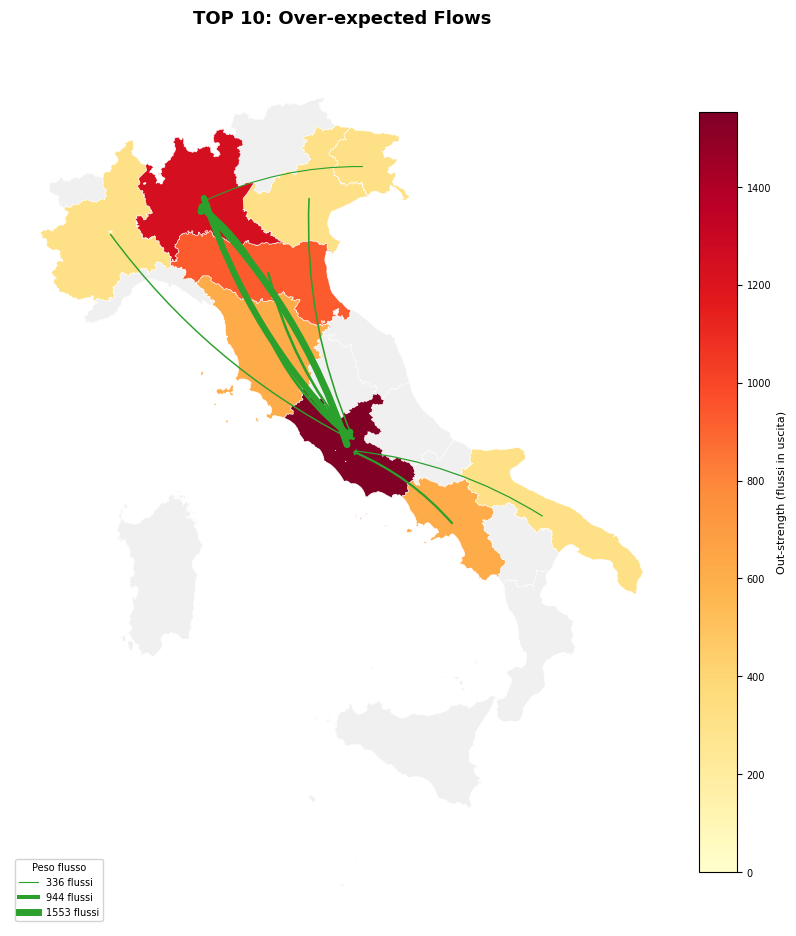

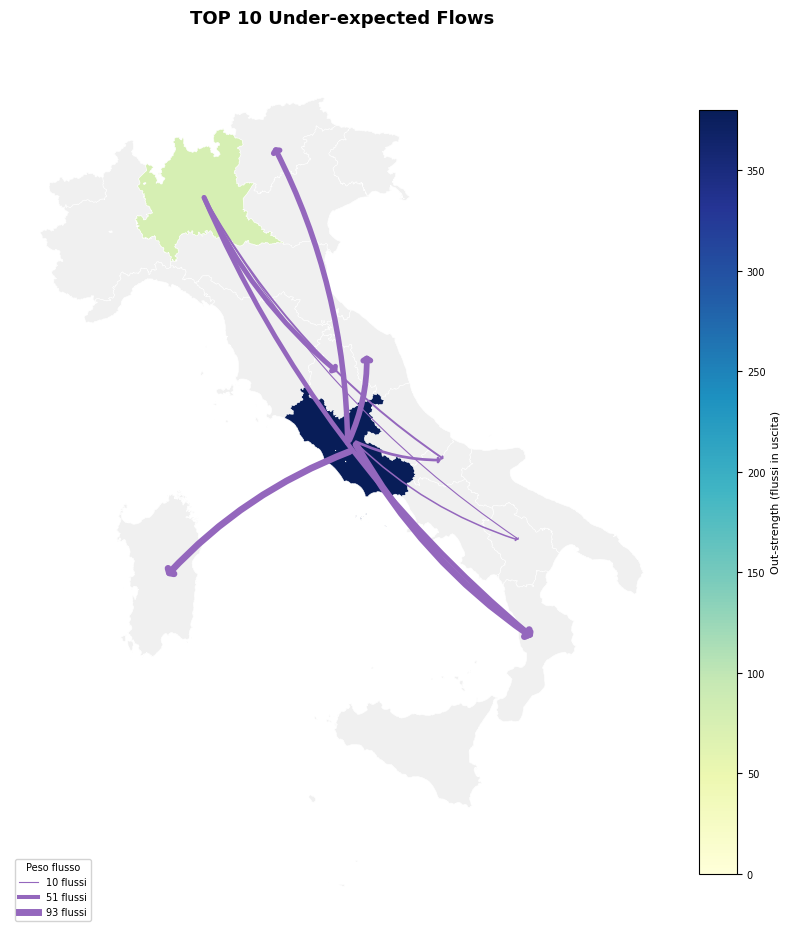

Mappe salvate come 'mappa_flussi_over.png' e 'mappa_flussi_under.png'
Mappe salvate come 'flussi_regionali_over_under.png' e '.pdf'


In [1]:
import pandas as pd
import networkx as nx
import json
import geopandas as gpd
import mapclassify
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from collections import defaultdict
from scipy.stats import norm

# ══════════════════════════════════════════════════════════════
# 1. CARICAMENTO DATI
# ══════════════════════════════════════════════════════════════

with open(
    'Step 3: Pulizia, trasformazione e analisi sullo storico/Pulizia storico/storico_pulito.json',
    'r'
) as f:
    data = json.load(f)

df = pd.read_csv(
    'Costruzione e Analisi DF/3. Data Understanding and Prep/df_understanding_analysis.csv'
)

# ══════════════════════════════════════════════════════════════
# 2. MAPPING REGIONI EN → IT
# ══════════════════════════════════════════════════════════════

mapping_regioni = {
    "Lombardy":              "Lombardia",
    "Lazio":                 "Lazio",
    "Tuscany":               "Toscana",
    "Emilia-Romagna":        "Emilia-Romagna",
    "Piedmont":              "Piemonte",
    "Veneto":                "Veneto",
    "Campania":              "Campania",
    "Sicily":                "Sicilia",
    "Apulia":                "Puglia",
    "Friuli Venezia Giulia": "Friuli-Venezia Giulia",
    "Trentino-Alto Adige":   "Trentino-Alto Adige/Südtirol",
    "Liguria":               "Liguria",
    "Abruzzo":               "Abruzzo",
    "Sardinia":              "Sardegna",
    "Calabria":              "Calabria",
    "The Marches":           "Marche",
    "Umbria":                "Umbria",
    "Basilicate":            "Basilicata",
    "Molise":                "Molise",
    "Aosta Valley":          "Valle d'Aosta/Vallée d'Aoste",
}
df['regione_it'] = df['regione'].map(mapping_regioni)

# ══════════════════════════════════════════════════════════════
# 3. ESTRAZIONE FLUSSI TEMPORALI
# ══════════════════════════════════════════════════════════════

def extract_flows_temporal(data, start_year=2020, end_year=2024):
    edges = []
    years = list(range(start_year, end_year))

    def get_names(lst):
        names = []
        for x in lst:
            if isinstance(x, dict):
                names.append(x.get("nome_istituzione"))
            else:
                names.append(x)
        return set([n for n in names if n])

    for autore, anni in data.items():
        for y in years:
            y1, y2 = str(y), str(y + 1)
            if y1 not in anni or y2 not in anni:
                continue
            inst1 = get_names(anni[y1])
            inst2 = get_names(anni[y2])
            stayed  = inst1.intersection(inst2)
            left    = inst1 - stayed
            entered = inst2 - stayed
            for u in left:
                for v in entered:
                    edges.append({'source': u, 'target': v,
                                  'year_from': y1, 'year_to': y2})
    return pd.DataFrame(edges)


df_edges    = extract_flows_temporal(data, start_year=2020, end_year=2024)
df_weighted = df_edges.groupby(['source', 'target']).size().reset_index(name='weight')
G           = nx.from_pandas_edgelist(
    df_weighted, source='source', target='target',
    edge_attr='weight', create_using=nx.DiGraph()
)

# ══════════════════════════════════════════════════════════════
# 4. AGGREGAZIONE A LIVELLO REGIONALE
# ══════════════════════════════════════════════════════════════

inst_to_region = dict(zip(df['nome_istituzione'], df['regione_it']))
flows_region   = defaultdict(float)

for u, v, d in G.edges(data=True):
    reg_u = inst_to_region.get(u)
    reg_v = inst_to_region.get(v)
    if reg_u and reg_v and reg_u != reg_v:
        flows_region[(reg_u, reg_v)] += d['weight']

G_reg = nx.DiGraph()
for (u, v), w in flows_region.items():
    G_reg.add_edge(u, v, weight=w)

# ══════════════════════════════════════════════════════════════
# 5. ANALISI STATISTICA (TEST RANDOMIZZAZIONE)
# ══════════════════════════════════════════════════════════════

def run_network_analysis(G, iterations=1000, alpha=0.05):
    edges        = list(G.edges())
    real_weights = np.array([G[u][v]['weight'] for u, v in edges])

    out_strength = {
        u: sum(d['weight'] for _, _, d in G.out_edges(u, data=True))
        for u in G.nodes()
    }
    out_degree = {u: G.out_degree(u) for u in G.nodes()}
    random_matrix = np.zeros((iterations, len(edges)))

    for i in range(iterations):
        for j, (u, v) in enumerate(edges):
            k = out_degree[u]
            s = out_strength[u]
            if k == 0 or s == 0:
                random_matrix[i, j] = 0
                continue
            probs   = np.ones(k) / k
            sampled = np.random.multinomial(int(s), probs)
            targets = list(G.successors(u))
            idx     = targets.index(v)
            random_matrix[i, j] = sampled[idx]

    means   = random_matrix.mean(axis=0)
    stds    = random_matrix.std(axis=0)
    z_scores = (real_weights - means) / np.where(stds < 1e-9, 1e-9, stds)
    p_values = 2 * (1 - norm.cdf(np.abs(z_scores)))

    results = pd.DataFrame({
        'source':      [e[0] for e in edges],
        'target':      [e[1] for e in edges],
        'real_weight': real_weights,
        'expected':    means,
        'z_score':     z_scores,
        'p_value':     p_values,
        'significant': p_values < alpha,
        'direction':   np.where(z_scores > 0, 'over', 'under'),
    })
    return results.sort_values('p_value')


final_results     = run_network_analysis(G_reg)
significant_flows = final_results[final_results['significant']].copy()

# ══════════════════════════════════════════════════════════════
# 6. GEODATI
# ══════════════════════════════════════════════════════════════

# ⚠️  Usiamo EPSG:4326 (gradi decimali, lon≈6-18, lat≈36-47) invece di
# EPSG:3857 (metri, ~10^6-10^7): matplotlib calcola la dimensione del
# renderer dalle coordinate degli artisti *prima* di applicare set_xlim,
# quindi coordinate enormi → MemoryError anche con limiti corretti.
regions = gpd.read_file(
    "https://raw.githubusercontent.com/openpolis/geojson-italy/"
    "master/geojson/limits_IT_regions.geojson"
).to_crs("EPSG:4326")

# ══════════════════════════════════════════════════════════════
# 7. FUNZIONE DISEGNO MAPPA
# ══════════════════════════════════════════════════════════════

COLOR_OVER  = '#2CA02C' # arancione caldo  → flussi sovra-attesi
COLOR_UNDER = '#9467BD'  # blu freddo       → flussi sotto-attesi


def _compute_choropleth_strength(flows_df, regions_gdf):
    """Aggiunge out_strength totale dei flussi significativi al GeoDataFrame."""
    strength = (
        flows_df.groupby('source')['real_weight']
        .sum()
        .reset_index()
        .rename(columns={'source': 'reg_name', 'real_weight': 'out_strength'})
    )
    gdf = regions_gdf.merge(strength, on='reg_name', how='left')
    gdf['out_strength'] = gdf['out_strength'].fillna(0)
    return gdf


def _arrow_params(weight, w_min, w_max,
                  lw_min=0.8, lw_max=5.0,
                  head_min=0.08, head_max=0.30):
    """Normalizza linewidth e head_width in base al peso del flusso.
    head_min/max sono in gradi decimali (unità EPSG:4326).
    """
    t = 0.5 if w_max == w_min else (weight - w_min) / (w_max - w_min)
    lw     = lw_min + t * (lw_max - lw_min)
    head_w = head_min + t * (head_max - head_min)
    head_l = head_w * 0.6
    return lw, head_w, head_l


def plot_flow_map(flows_df, direction: str, regions_gdf: gpd.GeoDataFrame,
                  title: str, arrow_color: str, cmap_name: str,
                  ax: plt.Axes):
    """
    Disegna una mappa coropleth con frecce di flusso.

    Parameters
    ----------
    flows_df    : DataFrame dei flussi (già filtrato per direction)
    direction   : 'over' | 'under'
    regions_gdf : GeoDataFrame in EPSG:4326
    title       : titolo del pannello
    arrow_color : colore HEX delle frecce
    cmap_name   : nome colormap matplotlib per il choropleth
    ax          : Axes matplotlib
    """

    # — Choropleth —
    gdf = _compute_choropleth_strength(flows_df, regions_gdf.copy())

    nonzero = gdf[gdf['out_strength'] > 0]['out_strength']
    if len(nonzero) >= 2:
        k      = min(5, len(nonzero.unique()))
        scheme = mapclassify.NaturalBreaks(nonzero, k=k)
        gdf['cls'] = scheme.find_bin(gdf['out_strength'])
    else:
        gdf['cls'] = 0

    max_cls = gdf['cls'].max() if gdf['cls'].max() > 0 else 1
    cmap    = plt.get_cmap(cmap_name)

    # Regioni senza flussi: grigio chiaro
    gdf_zero    = gdf[gdf['out_strength'] == 0]
    gdf_nonzero = gdf[gdf['out_strength'] > 0]

    gdf_zero.plot(ax=ax, color='#f0f0f0', edgecolor='white', linewidth=0.4)
    for cls_val, group in gdf_nonzero.groupby('cls'):
        intensity = 0.2 + 0.8 * (cls_val / max_cls)
        group.plot(ax=ax, color=cmap(intensity), edgecolor='white', linewidth=0.4)

    # — Centroidi (in gradi decimali) —
    centroids = {
        row['reg_name']: (row['geometry'].centroid.x, row['geometry'].centroid.y)
        for _, row in regions_gdf.iterrows()
    }

    # — Frecce —
    flows_valid = flows_df[
        flows_df['source'].isin(centroids) &
        flows_df['target'].isin(centroids)
    ].copy()

    if flows_valid.empty:
        ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
        ax.axis('off')
        return

    w_min = flows_valid['real_weight'].min()
    w_max = flows_valid['real_weight'].max()

    for _, row in flows_valid.iterrows():
        sx, sy = centroids[row['source']]
        tx, ty = centroids[row['target']]

        lw, hw, hl = _arrow_params(row['real_weight'], w_min, w_max)

        # Offset laterale (in gradi) per separare flussi bidirezionali
        dx, dy = tx - sx, ty - sy
        length = np.hypot(dx, dy)
        if length == 0:
            continue
        perp_x = -dy / length
        perp_y =  dx / length
        offset = 0.08  # ~8 km a latitudini italiane

        sx2, sy2 = sx + perp_x * offset, sy + perp_y * offset
        tx2, ty2 = tx + perp_x * offset, ty + perp_y * offset

        ax.annotate(
            "",
            xy=(tx2, ty2),
            xytext=(sx2, sy2),
            arrowprops=dict(
                arrowstyle=f"->, head_width={hw:.3f}, head_length={hl:.3f}",
                color=arrow_color,
                lw=lw,
                shrinkA=3,
                shrinkB=3,
                connectionstyle="arc3,rad=0.12",
            ),
            annotation_clip=True,
        )

    # — Legenda spessore frecce —
    sample_weights = np.linspace(w_min, w_max, 3)
    legend_lines = []
    for w in sample_weights:
        lw_s, _, _ = _arrow_params(w, w_min, w_max)
        legend_lines.append(
            Line2D([0], [0], color=arrow_color, linewidth=lw_s,
                   label=f'{int(w)} flussi')
        )
    ax.legend(handles=legend_lines, title='Peso flusso',
              loc='lower left', fontsize=7, title_fontsize=7,
              framealpha=0.85, edgecolor='#cccccc')

    # — Colorbar —
    sm = ScalarMappable(
        cmap=cmap,
        norm=Normalize(vmin=0, vmax=gdf['out_strength'].max())
    )
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label('Out-strength (flussi in uscita)', fontsize=8)
    cbar.ax.tick_params(labelsize=7)

    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    ax.axis('off')


# ══════════════════════════════════════════════════════════════
# 8. DISEGNO FIGURE SEPARATE (TOP 10)
# ══════════════════════════════════════════════════════════════

# Preparazione dati Top 10 (come prima)
flows_over = (
    significant_flows[significant_flows['direction'] == 'over']
    .sort_values('z_score', ascending=False)
    .head(10)
)

flows_under = (
    significant_flows[significant_flows['direction'] == 'under']
    .sort_values('z_score', ascending=True)
    .head(10)
)


# --- FIGURA 1: FLUSSI SOVRA-ATTESI (OVER) ---
# Creiamo una figura singola, più grande (es. 14x10 pollici)
fig1, ax1 = plt.subplots(figsize=(14, 10))

plot_flow_map(
    flows_df    = flows_over,
    direction   = 'over',
    regions_gdf = regions,
    title       = 'TOP 10: Over-expected Flows\n',
    arrow_color = COLOR_OVER,
    cmap_name   = 'YlOrRd',
    ax          = ax1,
)

# Aggiustiamo i margini per non tagliare i titoli
plt.tight_layout(pad=3.0)

# Salviamo la prima mappa
fig1.savefig('mappa_flussi_over.png', dpi=150, bbox_inches='tight')
# fig1.savefig('mappa_flussi_over.pdf', bbox_inches='tight') # Opzionale per vettoriale


# --- FIGURA 2: FLUSSI SOTTO-ATTESI (UNDER) ---
# Creiamo una seconda figura separata
fig2, ax2 = plt.subplots(figsize=(14, 10))

plot_flow_map(
    flows_df    = flows_under,
    direction   = 'under',
    regions_gdf = regions,
    title       = 'TOP 10 Under-expected Flows\n',
    arrow_color = COLOR_UNDER,
    cmap_name   = 'YlGnBu',
    ax          = ax2,
)

# Aggiustiamo i margini
plt.tight_layout(pad=3.0)

# Salviamo la seconda mappa
fig2.savefig('mappa_flussi_under.png', dpi=150, bbox_inches='tight')
# fig2.savefig('mappa_flussi_under.pdf', bbox_inches='tight') # Opzionale per vettoriale

# Mostriamo entrambe (aprirà due finestre separate)
plt.show()

print("Mappe salvate come 'mappa_flussi_over.png' e 'mappa_flussi_under.png'")
print("Mappe salvate come 'flussi_regionali_over_under.png' e '.pdf'")

In [34]:
# Costruzione mappa
region_centroids = {}
for _, row in regions.iterrows():
    name = row['reg_name']
    centroid = row['geometry'].centroid
    region_centroids[name] = (centroid.x, centroid.y)

In [35]:
# Filtro dei flussi con normalizzazione
flows = significant_flows.copy()
flows = flows[
    flows['source'].isin(region_centroids) &
    flows['target'].isin(region_centroids)
].copy()

if flows.empty:
    raise ValueError(
        "Nessun flusso significativo con coordinate. "
        "Controlla l'allineamento dei nomi sopra."
    )

w = flows['real_weight'].values
w_min, w_max = w.min(), w.max()
thickness = 0.8 + 4.2 * (w - w_min) / (w_max - w_min + 1e-9)

COLOR_OVER  = '#E66100'
COLOR_UNDER = '#2C7BB6'

flows = flows.copy()
flows['color']     = flows['direction'].map({'over': COLOR_OVER, 'under': COLOR_UNDER})
flows['thickness'] = thickness

In [36]:
# 1. Assicurati che le regioni siano proiettate
regions = regions.to_crs("EPSG:3857")

# 2. Crea il dizionario dei centroidi usando ESATTAMENTE i nomi nel GeoJSON
# (Usa 'reg_name' o la colonna che contiene i nomi in italiano)
region_centroids = {
    row['reg_name']: (row['geometry'].centroid.x, row['geometry'].centroid.y)
    for _, row in regions.iterrows()
}

# 3. Verifica: questo stamperà i nomi che il codice si aspetta
print("Nomi validi per le frecce:", list(region_centroids.keys()))

Nomi validi per le frecce: ['Piemonte', "Valle d'Aosta/Vallée d'Aoste", 'Lombardia', 'Trentino-Alto Adige/Südtirol', 'Veneto', 'Friuli-Venezia Giulia', 'Liguria', 'Emilia-Romagna', 'Toscana', 'Umbria', 'Marche', 'Lazio', 'Abruzzo', 'Molise', 'Campania', 'Puglia', 'Basilicata', 'Calabria', 'Sicilia', 'Sardegna']


In [37]:
# Preparazione dei dati
regions_nonzero_all = regions[regions['out_strength'] > 0].copy()
k = min(5, len(regions_nonzero_all['out_strength'].unique()))
scheme = mapclassify.NaturalBreaks(regions_nonzero_all['out_strength'], k=k)
regions_nonzero_all['class'] = scheme.yb
max_class = regions_nonzero_all['class'].max()
cmap = plt.get_cmap('YlOrRd')

# Propaga 'class' su regions
regions = regions.merge(
    regions_nonzero_all[['reg_name', 'class']],
    on='reg_name', how='left'
)

flows_over  = significant_flows[significant_flows['direction'] == 'over'].copy()
flows_under = significant_flows[significant_flows['direction'] == 'under'].copy()

KeyError: 'out_strength'

In [ ]:
# 1. Filtriamo solo i flussi significativi
df_sig = final_results[final_results['significant'] == True].copy()

# 2. Aggreghiamo lo Z-Score totale in uscita e in entrata per regione
# Lo Z-score positivo indica "più del previsto", negativo "meno del previsto"
out_sig = df_sig.groupby('source')['z_score'].sum()
in_sig = df_sig.groupby('target')['z_score'].sum()

# Creiamo il DataFrame per lo Slope
slope_sig = pd.DataFrame({'Partenze_Anomale': out_sig, 'Arrivi_Anomali': in_sig}).fillna(0)

# Ordiniamo per l'impatto totale (somma assoluta dei due lati)
slope_sig['total_impact'] = slope_sig['Partenze_Anomale'].abs() + slope_sig['Arrivi_Anomali'].abs()
slope_sig = slope_sig.sort_values('total_impact', ascending=False).head(15) # Top 15 regioni

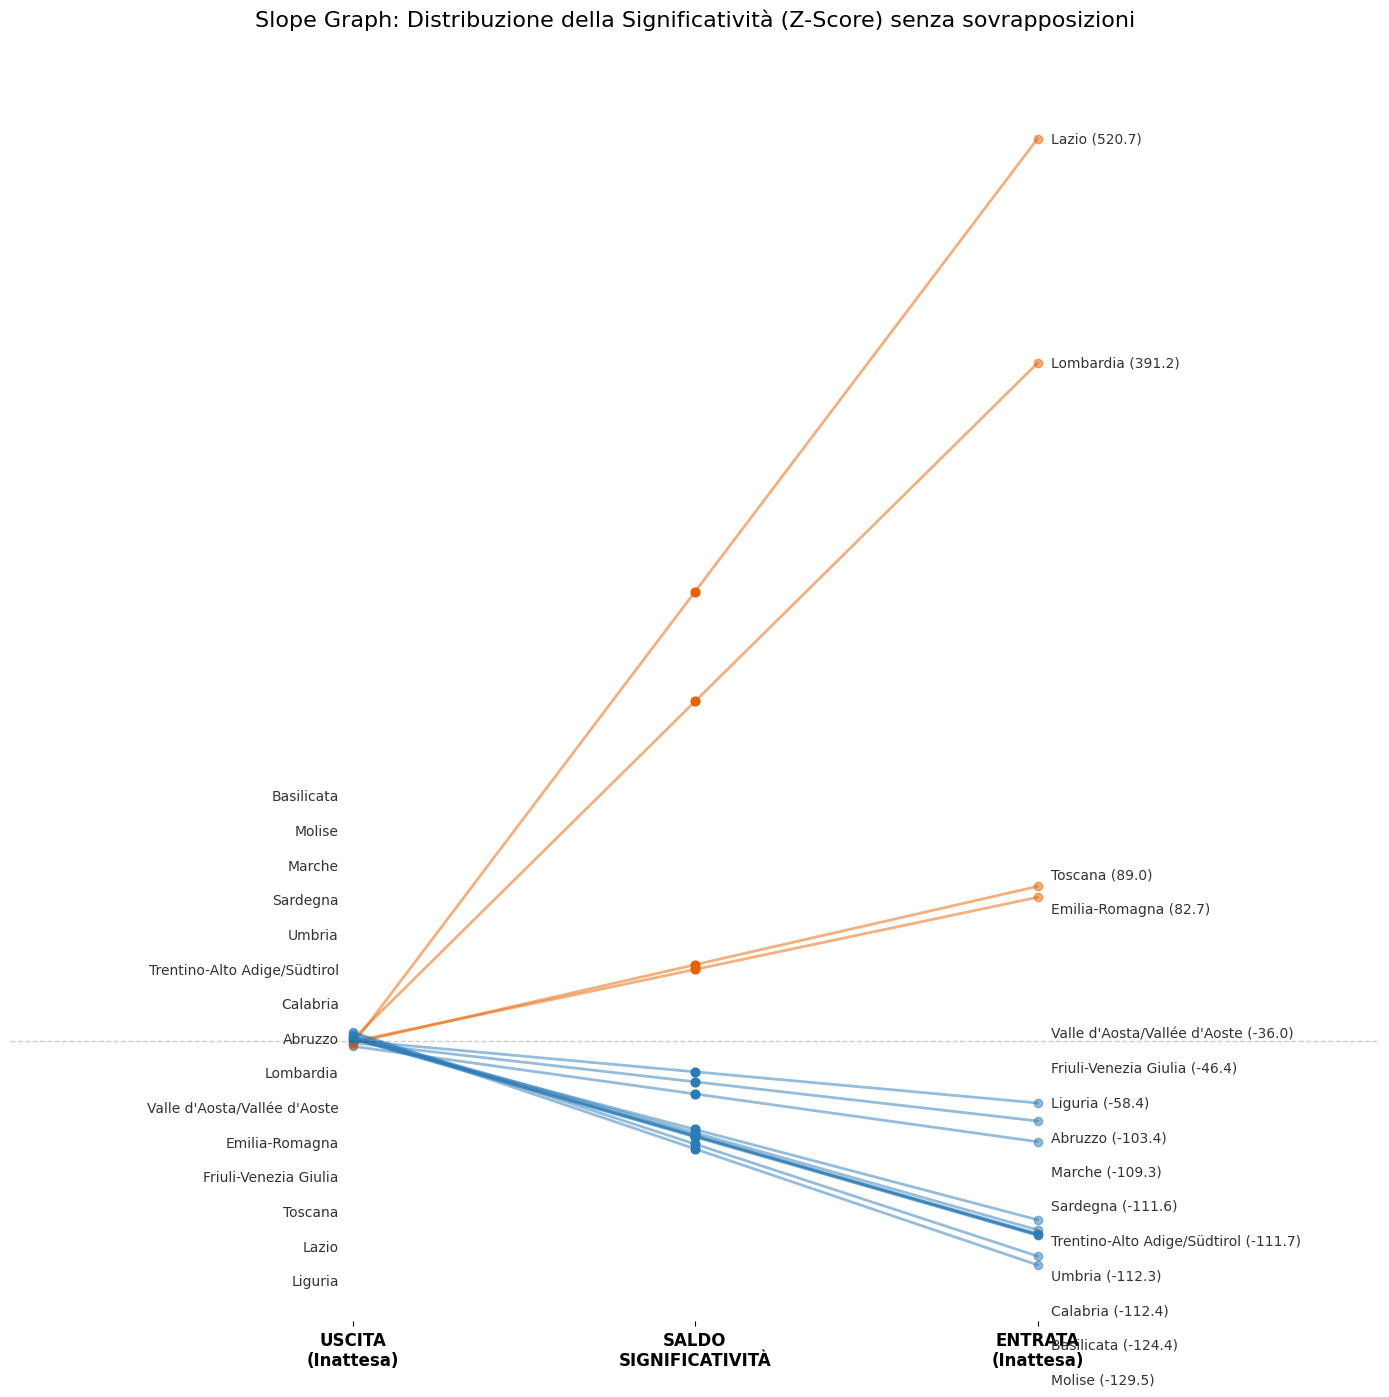

In [ ]:
def solve_overlap(pos_list, min_dist=15.0):
    """Sposta le posizioni Y per evitare sovrapposizioni."""
    n = len(pos_list)
    if n == 0: return pos_list
    # Ordina le posizioni
    new_pos = np.array(pos_list)
    for _ in range(1000): # Iterazioni per stabilizzare
        moved = False
        for i in range(n - 1):
            if new_pos[i+1] - new_pos[i] < min_dist:
                dist = min_dist - (new_pos[i+1] - new_pos[i])
                new_pos[i] -= dist / 2
                new_pos[i+1] += dist / 2
                moved = True
        if not moved: break
    return new_pos

# 1. Preparazione dati
# Assicurati che slope_sig sia ordinato per Arrivi_Anomali per facilitare il calcolo
data = slope_sig.sort_values('Partenze_Anomale').copy() # Ordina per il lato sinistro

fig, ax = plt.subplots(figsize=(14, 14))
ax.set_facecolor('white')

L, C, R = 0, 0.5, 1 

# Calcoliamo le posizioni Y ottimizzate per le etichette
y_left_raw = data['Partenze_Anomale'].values
y_right_raw = data['Arrivi_Anomali'].sort_values().values
labels_left = data.index.tolist()
labels_right = data.sort_values('Arrivi_Anomali').index.tolist()

# Applichiamo la funzione per distanziare i testi
# min_dist va regolato in base alla scala dello Z-score (proviamo con 15-20)
y_left_fixed = solve_overlap(y_left_raw, min_dist=20) 
y_right_fixed = solve_overlap(y_right_raw, min_dist=20)

# 2. Disegno delle linee e dei testi
for regione, row in data.iterrows():
    p1, p2 = row['Partenze_Anomale'], row['Arrivi_Anomali']
    net = p2 - p1
    color = '#E66100' if net > 0 else '#2C7BB6'
    
    # Linee e punti
    ax.plot([L, R], [p1, p2], marker='o', markersize=6, color=color, lw=2, alpha=0.5)
    ax.scatter(C, (p1+p2)/2, color=color, s=40, zorder=5)

# 3. Posizionamento etichette ottimizzato
for i in range(len(data)):
    # Etichette Sinistra
    ax.text(L - 0.02, y_left_fixed[i], labels_left[i], 
            ha='right', va='center', fontsize=10, color='#333333')
    # Etichette Destra
    ax.text(R + 0.02, y_right_fixed[i], f"{labels_right[i]} ({y_right_raw[i]:.1f})", 
            ha='left', va='center', fontsize=10, color='#333333')

# 4. Estetica finale
ax.axhline(0, color='black', lw=1, ls='--', alpha=0.2)
ax.set_xlim(-0.5, 1.5)
ax.set_xticks([L, C, R])
ax.set_xticklabels(['USCITA\n(Inattesa)', 'SALDO\nSIGNIFICATIVITÀ', 'ENTRATA\n(Inattesa)'], 
                   fontweight='bold', fontsize=12)

for spine in ax.spines.values(): spine.set_visible(False)
ax.get_yaxis().set_visible(False)

plt.title("Slope Graph: Distribuzione della Significatività (Z-Score) senza sovrapposizioni", 
          fontsize=16, pad=40)
plt.tight_layout()
plt.show()

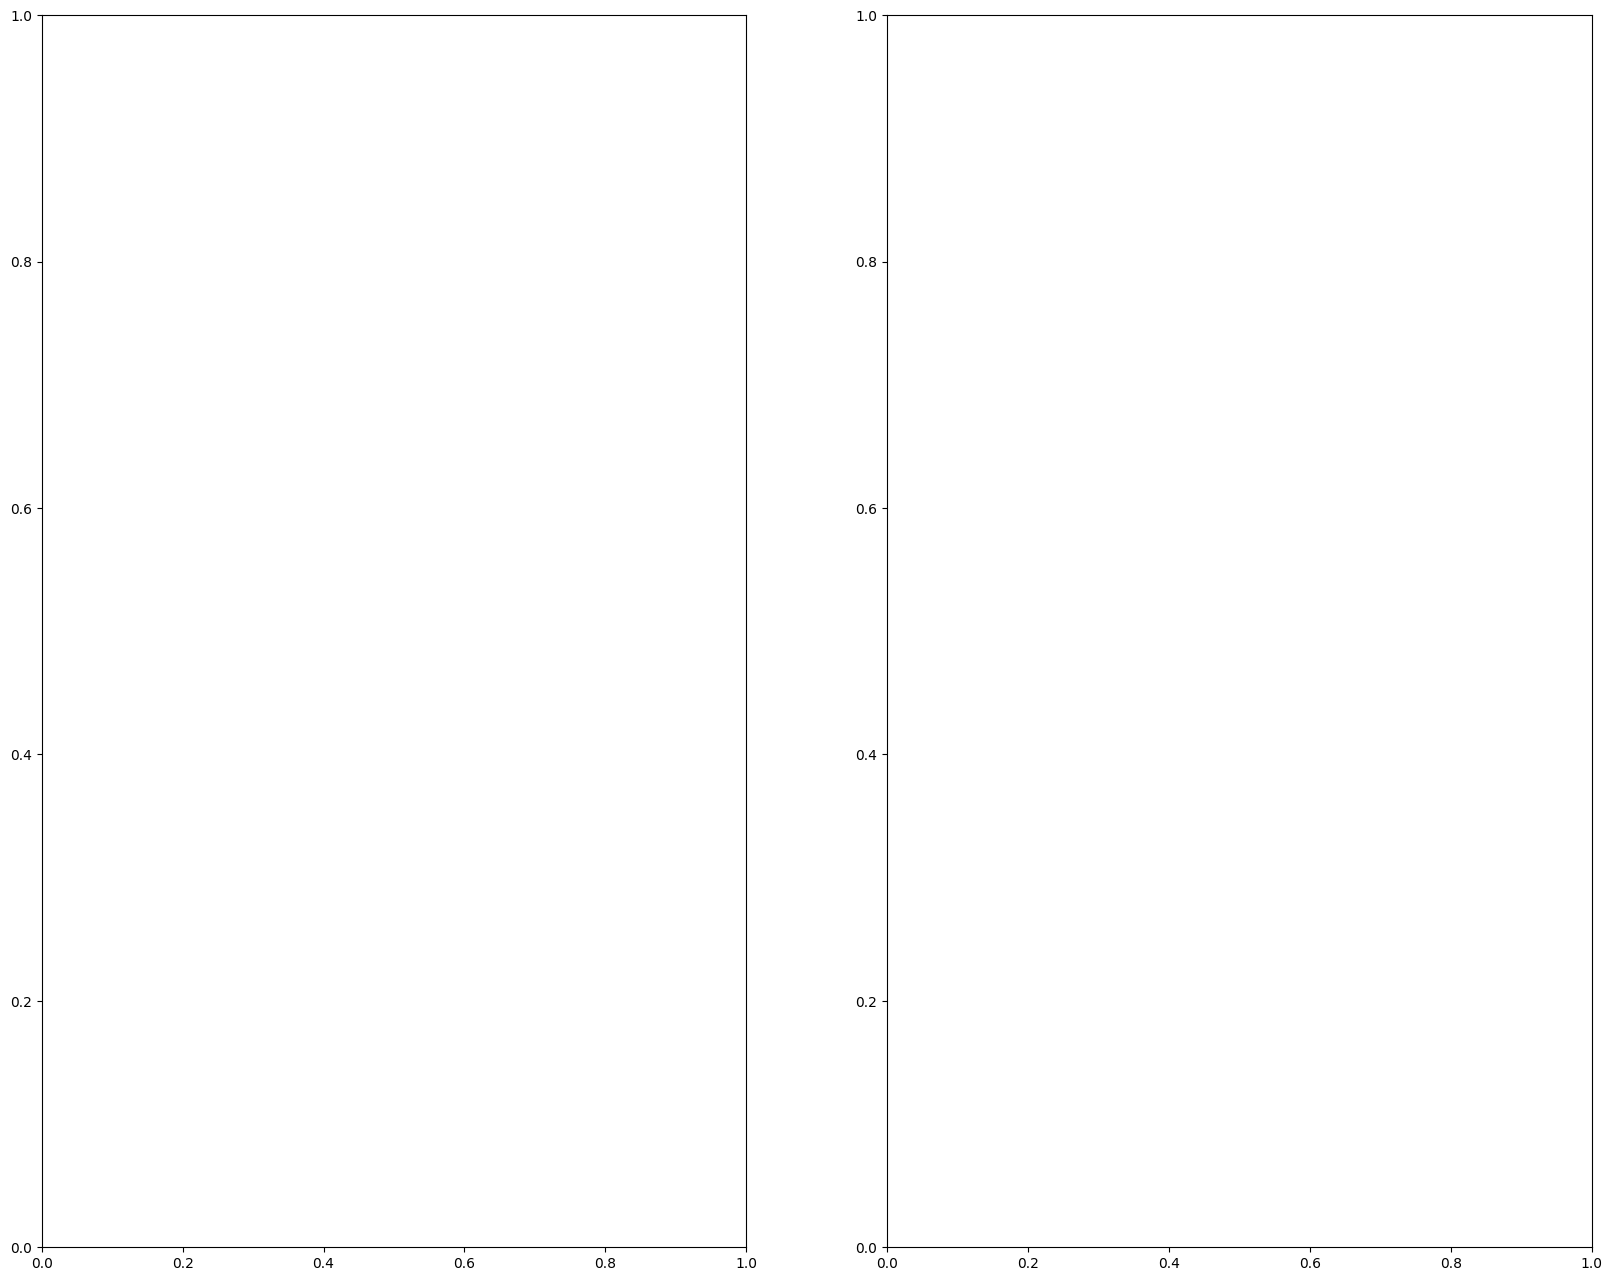

In [ ]:
# # Creazione della mappa
fig, axes = plt.subplots(1, 2, figsize=(20, 16))

def draw_map(ax, flows_subset, region_centroids, regions, cmap, scheme, max_class, title):
    
    # — Choropleth —
    regions_nonzero = regions[regions['out_strength'] > 0].copy()
    regions_zero    = regions[regions['out_strength'] == 0].copy()
    
    if not regions_nonzero.empty:
        regions_nonzero.plot(ax=ax, color='red')
    regions_zero.plot(ax=ax, color='#f0f0f0', edgecolor='gray', linewidth=0.4)

    # — Etichette regioni —
    for _, row in regions.iterrows():
        cx, cy = row['geometry'].centroid.x, row['geometry'].centroid.y
        ax.text(cx, cy, row['reg_name'], fontsize=5.5, ha='center', va='center',
                color='#333333', zorder=2)

    if flows_subset.empty:
        ax.set_title(title, fontsize=13, pad=10)
        _set_italy_bounds(ax)
        ax.axis('off')
        return

    w = flows_subset['real_weight'].values
    w_min, w_max = w.min(), w.max()

    # Spessore: scala NON lineare (radice quadrata) per enfatizzare gerarchia
    w_norm = (w - w_min) / (w_max - w_min + 1e-9)
    thickness = 0.5 + 5.5 * (w_norm ** 0.5)   # radice = più contrasto sui valori alti

    color = COLOR_OVER if 'Over' in title else COLOR_UNDER

    # — Frecce —
    for i, (_, row) in enumerate(flows_subset.iterrows()):
        x0, y0 = region_centroids[row['source']]
        x1, y1 = region_centroids[row['target']]

        dx, dy = x1 - x0, y1 - y0
        length = np.hypot(dx, dy) + 1e-9
        perp_x, perp_y = -dy / length, dx / length
        offset = 18000

        # Opacità proporzionale al peso (flussi deboli più trasparenti)
        alpha = 0.3 + 0.7 * w_norm[i]

        ax.annotate(
            "",
            xy    =(x1 + perp_x * offset, y1 + perp_y * offset),
            xytext=(x0 + perp_x * offset, y0 + perp_y * offset),
            arrowprops=dict(
                arrowstyle="-|>",
                color=color,
                lw=thickness[i],
                alpha=alpha,
                mutation_scale=10 + 8 * w_norm[i],   # punta freccia cresce col peso
                connectionstyle="arc3,rad=0.2"
            ),
            zorder=4
        )

    # — Nodi —
    all_nodes = set(flows_subset['source']) | set(flows_subset['target'])
    xs = [region_centroids[n][0] for n in all_nodes if n in region_centroids]
    ys = [region_centroids[n][1] for n in all_nodes if n in region_centroids]
    ax.scatter(xs, ys, s=35, color='white', edgecolors='black',
               linewidths=0.9, zorder=5)

    # — Legenda peso (solo spessore, niente colore) —
    # Mostra 3 livelli rappresentativi
    quantiles = np.quantile(w, [0.0, 0.5, 1.0])
    lw_q = [0.5 + 5.5 * ((q - w_min) / (w_max - w_min + 1e-9)) ** 0.5 for q in quantiles]
    leg_weight = [
        Line2D([0], [0], color='gray', lw=lw, label=f'{int(q)}')
        for q, lw in zip(quantiles, lw_q)
    ]
    ax.legend(handles=leg_weight, title='Peso flusso', title_fontsize=9,
              loc='lower left', bbox_to_anchor=(0.01, 0.01),
              frameon=True, facecolor='white', edgecolor='lightgray',
              fontsize=8, handlelength=2.5)

    ax.set_title(title, fontsize=13, pad=10, fontweight='bold', color=color)
    _set_italy_bounds(ax)
    ax.axis('off')
    print("Tot regions:", len(regions))
    print("Nonzero regions:", len(regions[regions['out_strength'] > 0]))
    print(regions[['reg_name','out_strength','class']].head())


def _set_italy_bounds(ax):
    transformer = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
    x_min, y_min = transformer.transform(6.0,  35.0)
    x_max, y_max = transformer.transform(19.0, 48.0)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect('equal')

In [ ]:
final_results.columns

Index(['source', 'target', 'real_weight', 'expected', 'z_score', 'p_value',
       'significant', 'direction'],
      dtype='object')

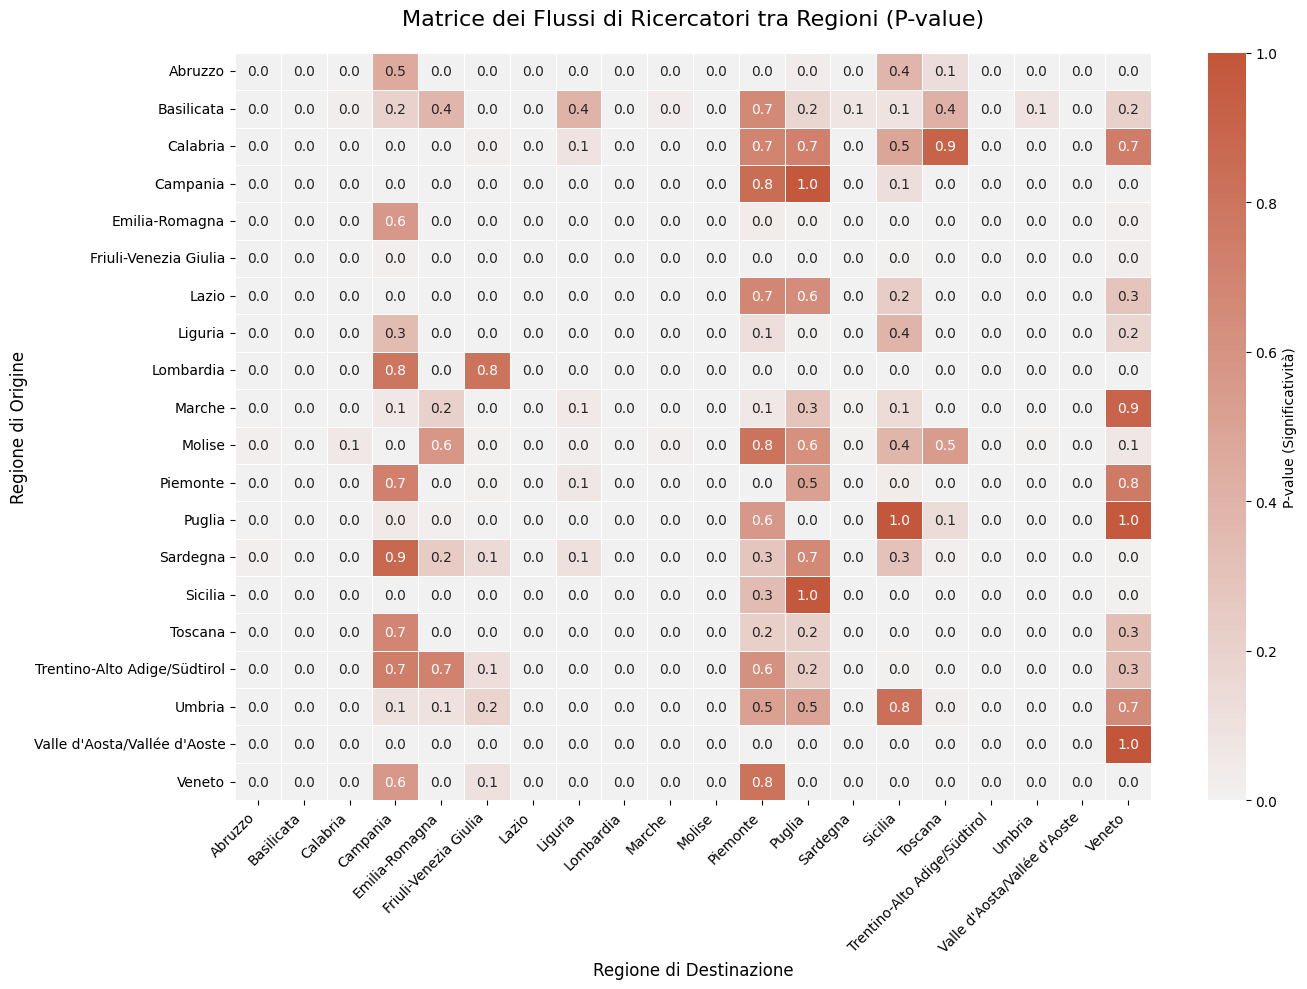

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Creiamo la matrice completa di tutte le regioni
# Usiamo pivot_table per sommare i pesi (o i p-values se preferisci)
matrix = final_results.pivot_table(
    index='source', 
    columns='target', 
    values='p_value',
    fill_value=0
)

# Ordiniamo le regioni alfabeticamente per facilità di lettura
matrix = matrix.sort_index(axis=0).sort_index(axis=1)

# 2. Configurazione del grafico
plt.figure(figsize=(14, 10))

# Creiamo una colormap divergente (Blu = Under, Rosso = Over)
cmap = sns.diverging_palette(240, 20, as_cmap=True)

# Disegniamo la heatmap
sns.heatmap(
    matrix, 
    annot=True,          # Mostra i valori numerici nelle celle
    fmt=".1f",           # Formato numeri (1 decimale)
    cmap=cmap, 
    center=0,            # Il bianco indica lo zero (flusso atteso)
    linewidths=.5, 
    cbar_kws={'label': 'P-value (Significatività)'}
)

plt.title('Matrice dei Flussi di Ricercatori tra Regioni (P-value)', fontsize=16, pad=20)
plt.xlabel('Regione di Destinazione', fontsize=12)
plt.ylabel('Regione di Origine', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
print(regions[['reg_name', 'out_strength', 'class']].head(10))
print(regions['class'].isna().sum(), "NaN su", len(regions))

                       reg_name  out_strength  class
0                      Piemonte        1239.0    2.0
1  Valle d'Aosta/Vallée d'Aoste           0.0    NaN
2                     Lombardia        4273.0    4.0
3  Trentino-Alto Adige/Südtirol         235.0    0.0
4                        Veneto        1381.0    2.0
5         Friuli-Venezia Giulia        1216.0    2.0
6                       Liguria         778.0    1.0
7                Emilia-Romagna        2243.0    3.0
8                       Toscana        1810.0    3.0
9                        Umbria         247.0    0.0
1 NaN su 20


In [ ]:
print(set(regions_nonzero_all['reg_name']) - set(regions['reg_name']))
print(set(regions['reg_name']) - set(regions_nonzero_all['reg_name']))

set()
{"Valle d'Aosta/Vallée d'Aoste"}


In [ ]:
# Disegnare le due mappe
draw_map(axes[0], flows_over,  region_centroids, regions, cmap, scheme, max_class,
         title='Flussi Over atteso')
draw_map(axes[1], flows_under, region_centroids, regions, cmap, scheme, max_class,
         title='Flussi Under atteso')

Tot regions: 20
Nonzero regions: 19
                       reg_name  out_strength  class
0                      Piemonte        1239.0    2.0
1  Valle d'Aosta/Vallée d'Aoste           0.0    NaN
2                     Lombardia        4273.0    4.0
3  Trentino-Alto Adige/Südtirol         235.0    0.0
4                        Veneto        1381.0    2.0
Tot regions: 20
Nonzero regions: 19
                       reg_name  out_strength  class
0                      Piemonte        1239.0    2.0
1  Valle d'Aosta/Vallée d'Aoste           0.0    NaN
2                     Lombardia        4273.0    4.0
3  Trentino-Alto Adige/Südtirol         235.0    0.0
4                        Veneto        1381.0    2.0


In [ ]:
# Disegnare legende e show plot
region_patches = [Patch(facecolor='#f0f0f0', edgecolor='gray', label='0')]
for i, bound in enumerate(scheme.bins):
    lower = int(scheme.bins[i-1] + 1) if i > 0 else int(regions_nonzero_all['out_strength'].min())
    color = cmap(i / max_class) if max_class > 0 else cmap(0)
    region_patches.append(Patch(facecolor=color, edgecolor='gray',
                                label=f"{lower}–{int(bound)}"))

fig.legend(handles=region_patches,
           title='Out-strength (flussi uscenti)',
           title_fontsize=10,
           loc='lower center',
           ncol=len(region_patches),
           bbox_to_anchor=(0.5, -0.01),
           frameon=False, fontsize=9)

fig.suptitle('Flussi inter-regionali significativi\nspessore + opacità = peso del flusso',
             fontsize=15, fontweight='bold', y=1.01)

plt.tight_layout()
plt.savefig('flow_map_split.png', dpi=180, bbox_inches='tight')
plt.show()

<Figure size 640x480 with 0 Axes>